# Bitcoin Alpha Generation via On-Chain & Macro ML Modelling
**Alpha Forge — Finance & Analytics Club, IIT Kanpur**

Dataset: `btc_alpha_master_2014_2026.csv` — 4,292 daily observations (17 Sep 2014 → 18 Jun 2026)

This notebook follows the six-step brief:
1. EDA on the Rhode feature set
2. Data preparation (missing values, normalisation, leak-free chronological split)
3. ML models predicting daily log returns
4. Alpha signal generation (Long/Short) and strategy simulation
5. Statistical evaluation (MAE, RMSE, Directional Accuracy, R²) + financial evaluation (Sharpe, Max Drawdown, Cumulative Return vs. buy-and-hold)
6. Feature importance interpretation

## 0. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
import glob
df = pd.read_csv('btc_alpha_master_2014_2026.csv', parse_dates=['Date'])
df = df.sort_values('Date').reset_index(drop=True)
print(f"Shape: {df.shape}")
print(f"Date range: {df['Date'].min().date()} -> {df['Date'].max().date()}")
df.head()

Shape: (4292, 16)
Date range: 2014-09-17 -> 2026-06-18


,Date,Open,High,Low,Close,Volume,AdrActCnt,FeeTotNtv,HashRate,SplyCur,TxCnt,DXY_Close,TNX_Yield,FeeTotUSD,True_Market_Cap,Fee_to_MCap
0,2014-09-17,465.864014,468.174011,452.421997,457.334015,21056800,191063.0,12.040404,275808.998243,1.328109e+07,78526.0,84.699997,2.600,5506.486407,6.073894e+09,9.065825e-07
1,2014-09-18,456.859985,456.859985,413.104004,424.440002,34483200,190890.0,12.215005,265429.089707,1.328556e+07,76357.0,84.320000,2.629,5184.536727,5.638925e+09,9.194193e-07
2,2014-09-19,424.102997,427.834991,384.532013,394.795990,37919700,172255.0,10.819493,253566.337094,1.328984e+07,70093.0,84.800003,2.587,4271.492549,5.246775e+09,8.141177e-07
3,2014-09-20,394.673004,423.295990,389.882996,408.903992,36863600,169941.0,10.303744,260980.557477,1.329424e+07,64168.0,84.800003,2.587,4213.242035,5.436068e+09,7.750533e-07
4,2014-09-21,408.084991,412.425995,393.181000,398.821014,26580100,200712.0,9.086879,243186.428558,1.329834e+07,57668.0,84.800003,2.587,3624.038141,5.303657e+09,6.833093e-07


In [3]:
df.isnull().sum().to_frame('missing_values').T

,Date,Open,High,Low,Close,Volume,AdrActCnt,FeeTotNtv,HashRate,SplyCur,TxCnt,DXY_Close,TNX_Yield,FeeTotUSD,True_Market_Cap,Fee_to_MCap
missing_values,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


No missing values anywhere in the raw file - one less thing to worry about in preprocessing.
This is unusual for a real on-chain/macro merge (macro series often have weekend/holiday gaps that
need forward-filling), so it's worth flagging: the dataset has likely already been forward-filled /
aligned to a continuous daily calendar upstream of what we received.

## 1. Constructing the Rhode Features

Two of the nine Rhode features — **Log Returns** (target) and **Rolling Volatility** — are not
provided directly and must be derived from `Close`:

- `Log_Returns = ln(Close_t / Close_{t-1})` — the target variable.
- `Rolling_Volatility` = rolling standard deviation of log returns over a 21-trading-day window
  (≈ 1 calendar month), used here as the "risk regime" normaliser the brief describes.

In [5]:
df['Log_Returns'] = np.log(df['Close'] / df['Close'].shift(1))

ROLL_WINDOW = 21
df['Rolling_Volatility'] = df['Log_Returns'].rolling(ROLL_WINDOW).std()

rhode_features = ['True_Market_Cap', 'FeeTotUSD', 'Fee_to_MCap', 'DXY_Close',
                   'TNX_Yield', 'AdrActCnt', 'HashRate', 'Rolling_Volatility']
target = 'Log_Returns'

df[rhode_features + [target]].describe().T

,count,mean,std,min,25%,50%,75%,max
True_Market_Cap,4292.0,5.572136e+11,6.456098e+11,2.444377e+09,6.026113e+10,2.126317e+11,8.830909e+11,2.486432e+12
FeeTotUSD,4292.0,1.032235e+06,2.452485e+06,2.490217e+03,1.262363e+05,3.736121e+05,8.243822e+05,7.841362e+07
Fee_to_MCap,4292.0,3.674347e-06,6.220596e-06,8.120084e-08,7.842773e-07,1.479972e-06,3.907962e-06,8.925815e-05
DXY_Close,4292.0,9.806156e+01,5.024860e+00,8.432000e+01,9.469750e+01,9.761000e+01,1.014100e+02,1.141100e+02
TNX_Yield,4292.0,2.699831e+00,1.144393e+00,4.990000e-01,1.813500e+00,2.418000e+00,3.866000e+00,4.988000e+00
AdrActCnt,4292.0,7.276061e+05,2.336767e+05,1.457650e+05,5.952845e+05,7.362480e+05,9.064678e+05,1.366494e+06
HashRate,4292.0,2.553980e+08,3.239871e+08,2.224266e+05,6.828497e+06,1.160193e+08,3.793219e+08,1.305500e+09
Rolling_Volatility,4271.0,3.119431e-02,1.589974e-02,5.705039e-03,2.014794e-02,2.796774e-02,3.840878e-02,1.216363e-01
Log_Returns,4291.0,1.152977e-03,3.511216e-02,-4.647302e-01,-1.268641e-02,1.050323e-03,1.575885e-02,2.251190e-01


### 1.1 Economic rationale recap (per the brief)

| Feature | Layer | What it captures |
|---|---|---|
| `True_Market_Cap` | On-chain valuation | price × precise circulating supply |
| `FeeTotUSD` | Network utility | blockchain demand / congestion, in USD |
| `Fee_to_MCap` | Valuation ratio | crypto-native "P/E" — fee revenue relative to network value |
| `DXY_Close` | Macro liquidity | inverse proxy for global dollar liquidity |
| `TNX_Yield` | Macro rates | risk-free rate proxy / opportunity cost of speculative capital |
| `AdrActCnt` | Adoption | unique active addresses — organic usage vs. pure speculation |
| `HashRate` | Security | mining investment — proxies miner confidence and a cost-support floor |
| `Rolling_Volatility` | Risk normaliser | recent realized volatility — flags high-uncertainty regimes |
| `Log_Returns` | **Target** | what every model below tries to predict |

## 2. Exploratory Data Analysis

### 2.1 Price history and market regimes

The brief asks us to examine how features behave "across different market regimes (bull, bear,
consolidation, macro shock)". We first map out BTC's regime history so later analysis (e.g. feature
correlations, model errors) can be read against it.

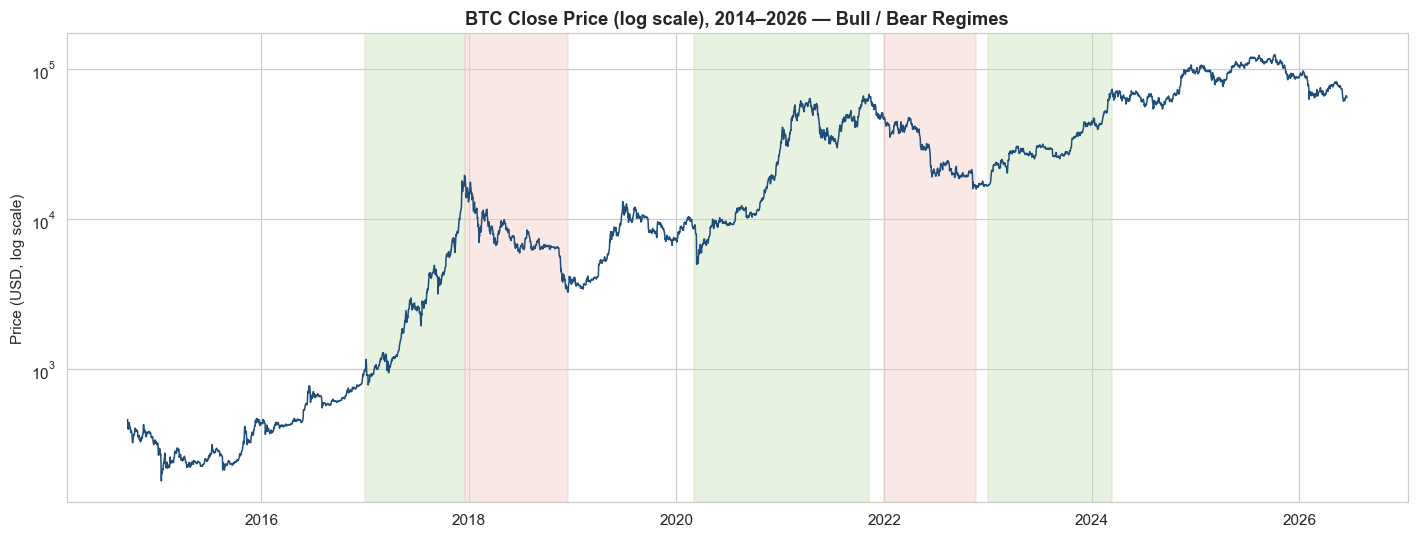

In [6]:
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(df['Date'], df['Close'], color='#1f4e79', linewidth=1)
ax.set_yscale('log')
ax.set_title('BTC Close Price (log scale), 2014–2026 — Bull / Bear Regimes', fontweight='bold')
ax.set_ylabel('Price (USD, log scale)')

regimes = [
    ('2017-01-01', '2017-12-17', '#c6e0b4', 'Bull (2017 mania)'),
    ('2017-12-17', '2018-12-15', '#f4c7c3', 'Bear (2018 crash)'),
    ('2020-03-01', '2021-11-10', '#c6e0b4', 'Bull (COVID-era QE)'),
    ('2022-01-01', '2022-11-21', '#f4c7c3', 'Bear (rate-hike cycle)'),
    ('2023-01-01', '2024-03-14', '#c6e0b4', 'Recovery / Bull'),
]
for start, end, color, label in regimes:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=color, alpha=0.4)
ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.tight_layout()
plt.show()

Visible regimes: the 2017 retail mania and its 2018 unwind, the COVID-liquidity-driven 2020–21
bull run, the 2022 Fed rate-hike bear market, and a 2023–24 recovery into new highs — followed by a
2025–26 drawdown in the most recent data. The 2022 bear and 2018 bear line up closely with rising
`TNX_Yield` / `DXY_Close`, consistent with the macro-liquidity rationale given for those two features.

### 2.2 Distribution of log returns — fat tails, not normal

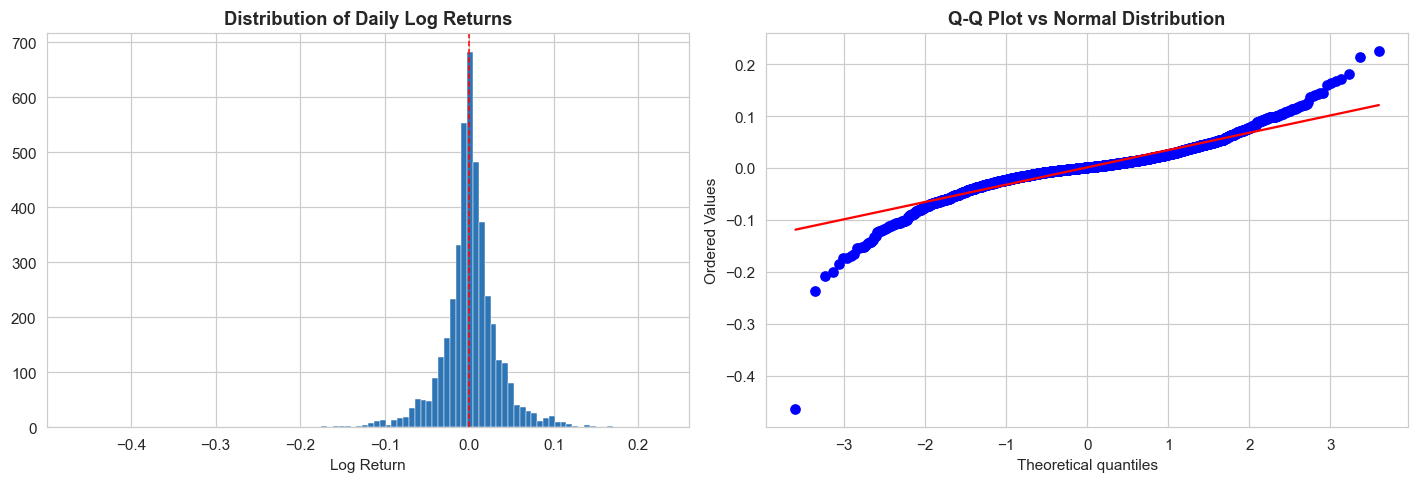

Skew: -0.707   Kurtosis (excess): 11.835


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df['Log_Returns'].dropna(), bins=100, color='#2e75b6', edgecolor='white', linewidth=0.3)
axes[0].set_title('Distribution of Daily Log Returns', fontweight='bold')
axes[0].set_xlabel('Log Return')
axes[0].axvline(0, color='red', linestyle='--', linewidth=1)

stats.probplot(df['Log_Returns'].dropna(), dist='norm', plot=axes[1])
axes[1].set_title('Q-Q Plot vs Normal Distribution', fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Skew: {df['Log_Returns'].skew():.3f}   Kurtosis (excess): {df['Log_Returns'].kurt():.3f}")

Excess kurtosis confirms the well-known stylised fact for crypto (and most financial) returns:
**fat tails**. The Q-Q plot bows away from the reference line at both ends — large moves are far
more frequent than a Gaussian model would predict. This matters downstream: (a) MSE-based loss
functions are sensitive to these tail observations, and (b) Sharpe ratios computed on fat-tailed
return series understate true tail risk, which is why we also report Max Drawdown.

### 2.3 Rhode features over time

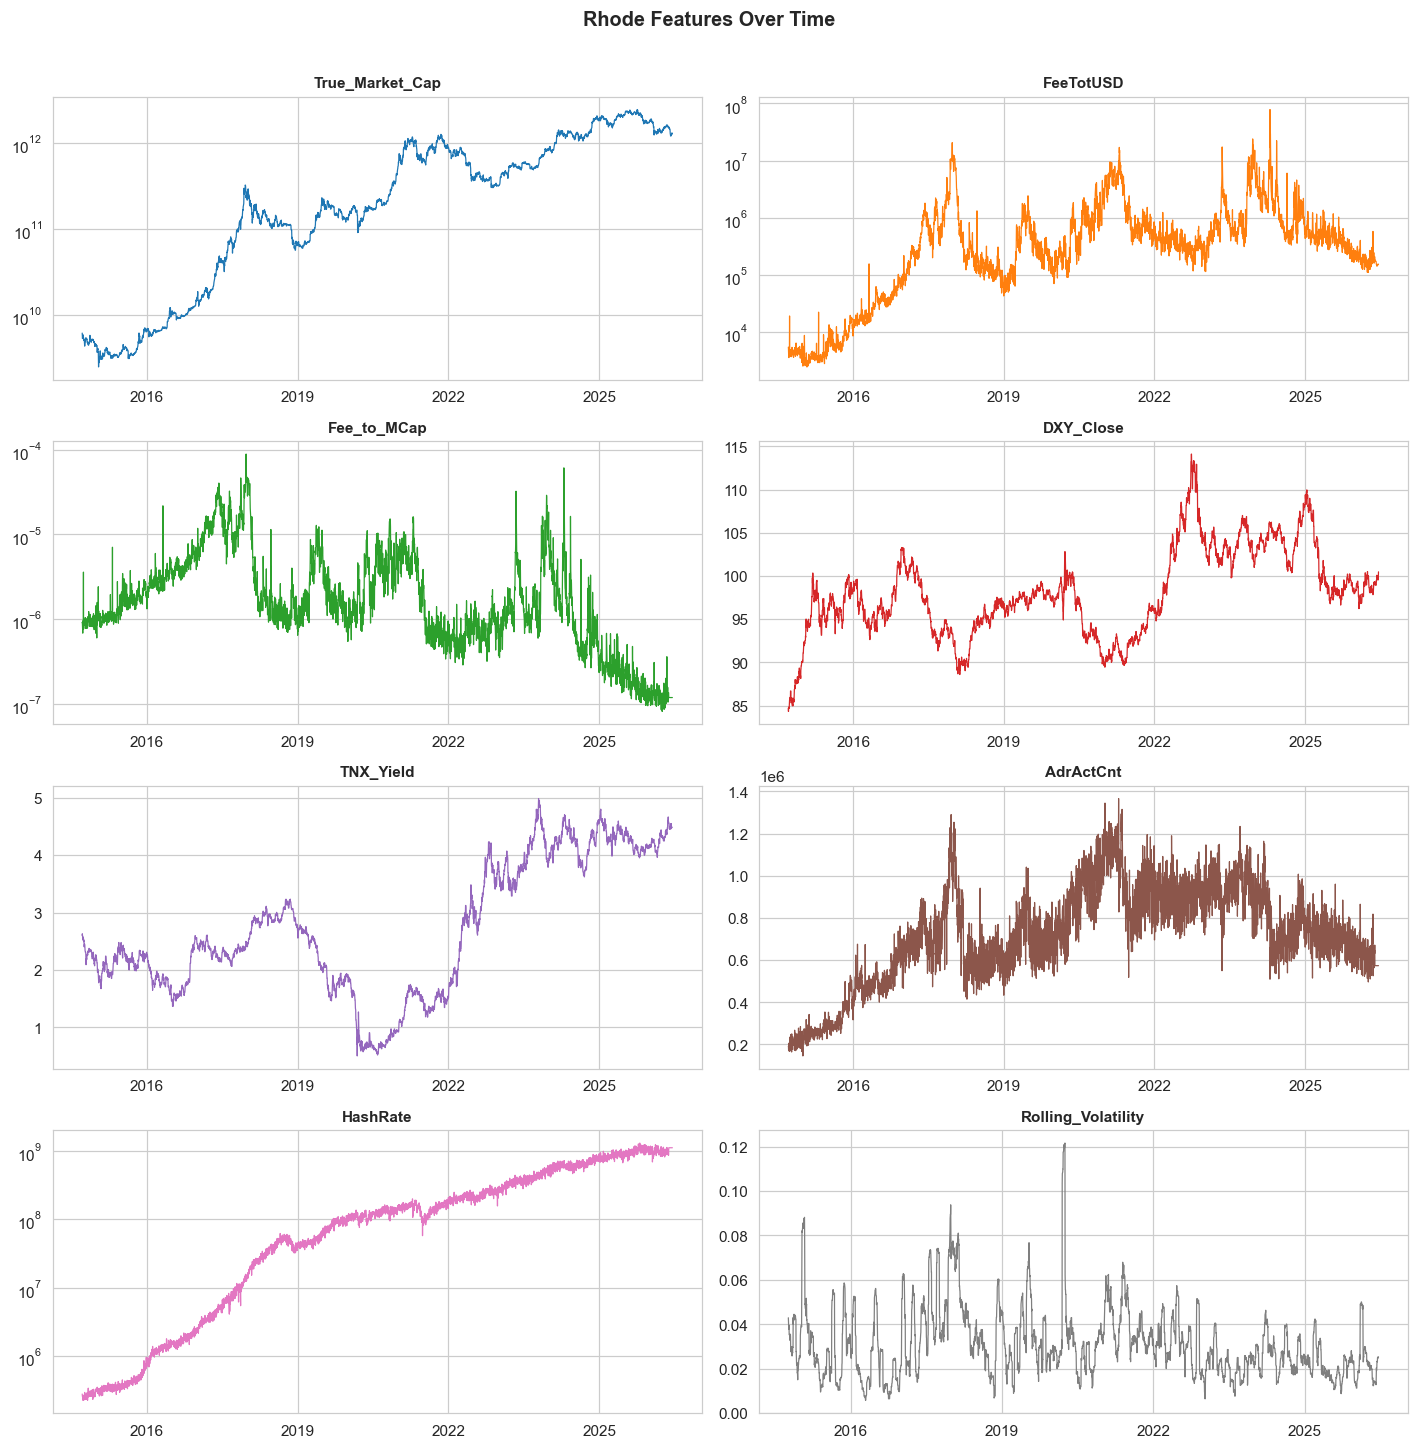

In [8]:
fig, axes = plt.subplots(4, 2, figsize=(13, 13))
axes = axes.flatten()
colors = sns.color_palette('tab10', 8)
for i, f in enumerate(rhode_features):
    axes[i].plot(df['Date'], df[f], color=colors[i], linewidth=0.8)
    axes[i].set_title(f, fontsize=10, fontweight='bold')
    if df[f].min() > 0 and df[f].max() / max(df[f].min(), 1e-12) > 100:
        axes[i].set_yscale('log')
    axes[i].xaxis.set_major_locator(mdates.YearLocator(3))
plt.suptitle('Rhode Features Over Time', fontweight='bold', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

`True_Market_Cap` and `HashRate` both grow ~4 orders of magnitude over the sample and trend
together — a strong hint of the multicollinearity confirmed in the correlation matrix next.
`DXY_Close` and `TNX_Yield` show clear macro-regime structure (the 2022 Fed hiking cycle is visible
as a sharp `TNX_Yield` step-up). `Fee_to_MCap` spikes during congestion events (e.g. 2017, 2021/2023
NFT and Ordinals-driven fee surges) even when price itself is flat or falling.

### 2.4 Stationarity (Augmented Dickey-Fuller test)

In [9]:
def adf_test(series, name):
    series = series.dropna()
    result = stats_adfuller(series)
    return {'feature': name, 'ADF_stat': result[0], 'p_value': result[1],
            'stationary_at_5%': result[1] < 0.05}

from statsmodels.tsa.stattools import adfuller as stats_adfuller

results = [adf_test(df[f], f) for f in rhode_features + [target]]
adf_levels = pd.DataFrame(results)
adf_levels

,feature,ADF_stat,p_value,stationary_at_5%
0,True_Market_Cap,-1.260131,6.472093e-01,False
1,FeeTotUSD,-6.142624,7.904046e-08,True
2,Fee_to_MCap,-5.223396,7.874911e-06,True
3,DXY_Close,-3.082083,2.790783e-02,True
4,TNX_Yield,-0.705777,8.452476e-01,False
5,AdrActCnt,-2.570638,9.921889e-02,False
6,HashRate,2.733150,9.990880e-01,False
7,Rolling_Volatility,-6.365234,2.419039e-08,True
8,Log_Returns,-19.906551,0.000000e+00,True


As expected, the trending level variables (`True_Market_Cap`, `TNX_Yield`, `AdrActCnt`, `HashRate`)
**fail to reject** the unit-root null — they are non-stationary in raw level form. `Log_Returns` and
`Rolling_Volatility` are comfortably stationary, as is `Fee_to_MCap` and `DXY_Close` (mean-reverting
macro/ratio series). We confirm below that first-differencing (or log-differencing for strictly
positive level variables) resolves this for every non-stationary feature.

In [10]:
diff_results = []
for f in ['True_Market_Cap', 'FeeTotUSD', 'AdrActCnt', 'HashRate']:
    diff_results.append(adf_test(np.log(df[f]).diff(), f'log({f}).diff()'))
for f in ['DXY_Close', 'TNX_Yield', 'Fee_to_MCap']:
    diff_results.append(adf_test(df[f].diff(), f'{f}.diff()'))
pd.DataFrame(diff_results)

,feature,ADF_stat,p_value,stationary_at_5%
0,log(True_Market_Cap).diff(),-19.904000,0.000000e+00,True
1,log(FeeTotUSD).diff(),-13.527955,2.655803e-25,True
2,log(AdrActCnt).diff(),-15.722603,1.318379e-28,True
3,log(HashRate).diff(),-23.803332,0.000000e+00,True
4,DXY_Close.diff(),-65.784235,0.000000e+00,True
5,TNX_Yield.diff(),-48.051822,0.000000e+00,True
6,Fee_to_MCap.diff(),-12.659837,1.312249e-23,True


All eight differenced series are now stationary at the 5% level. **This is why our modelling features
(Section 3) use differenced/log-differenced versions of the level variables, not the raw levels** —
using raw non-stationary levels as ML inputs is a common and avoidable mistake in finance ML.

### 2.5 Correlation structure

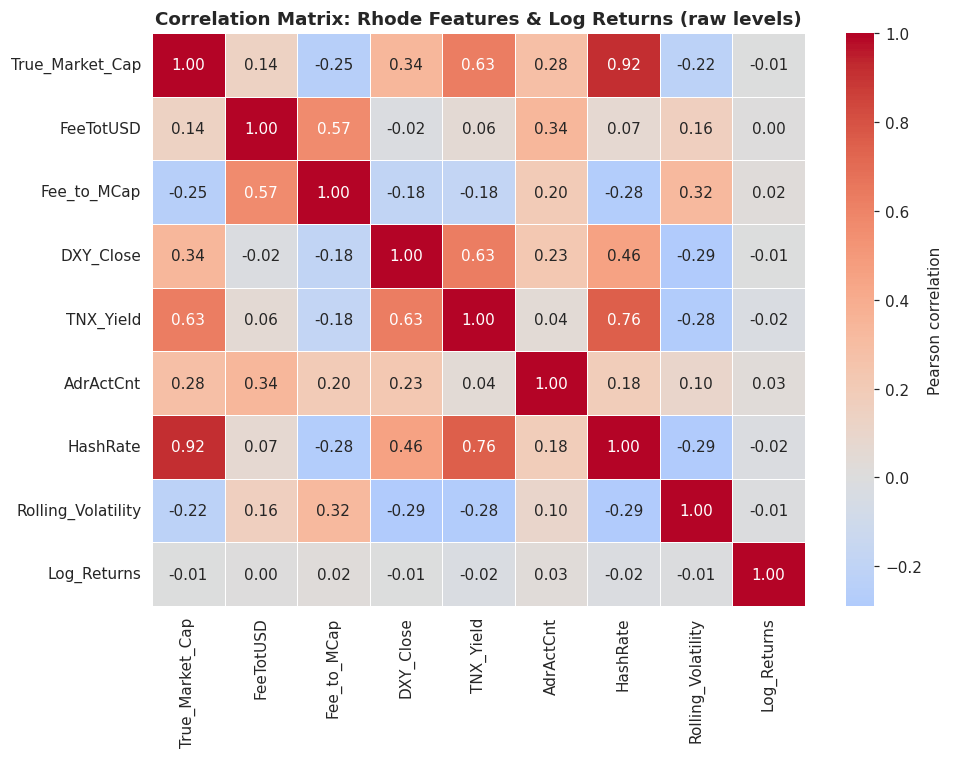

In [10]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = df[rhode_features + ['Log_Returns']].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            cbar_kws={'label': 'Pearson correlation'}, linewidths=0.5)
ax.set_title('Correlation Matrix: Rhode Features & Log Returns (raw levels)', fontweight='bold')
plt.tight_layout()
plt.show()

Two things stand out:

1. **Severe multicollinearity among levels**: `HashRate` ↔ `True_Market_Cap` (ρ=0.92),
   `HashRate` ↔ `TNX_Yield` (ρ=0.76), `TNX_Yield` ↔ `True_Market_Cap` (ρ=0.63). This is mechanical —
   all three have grown roughly monotonically over a 12-year sample — not necessarily a genuine causal
   economic link. Tree-based models are robust to this; linear models are not (coefficients become
   unstable / hard to interpret), which is one reason we lean on tree ensembles for feature-importance
   interpretation in Section 6 rather than raw linear coefficients.
2. **Essentially zero linear correlation between any raw feature and next-period `Log_Returns`**
   (|ρ| ≤ 0.03 for every feature). This previews the central result of the whole notebook: at daily
   frequency, BTC log returns behave close to a random walk with respect to these slow-moving
   fundamentals — consistent with an efficiently / quickly arbitraged market where on-chain and macro
   information is absorbed into price faster than a 1-day rebalancing strategy can exploit it.

### 2.6 Volatility clustering (risk regime behaviour)

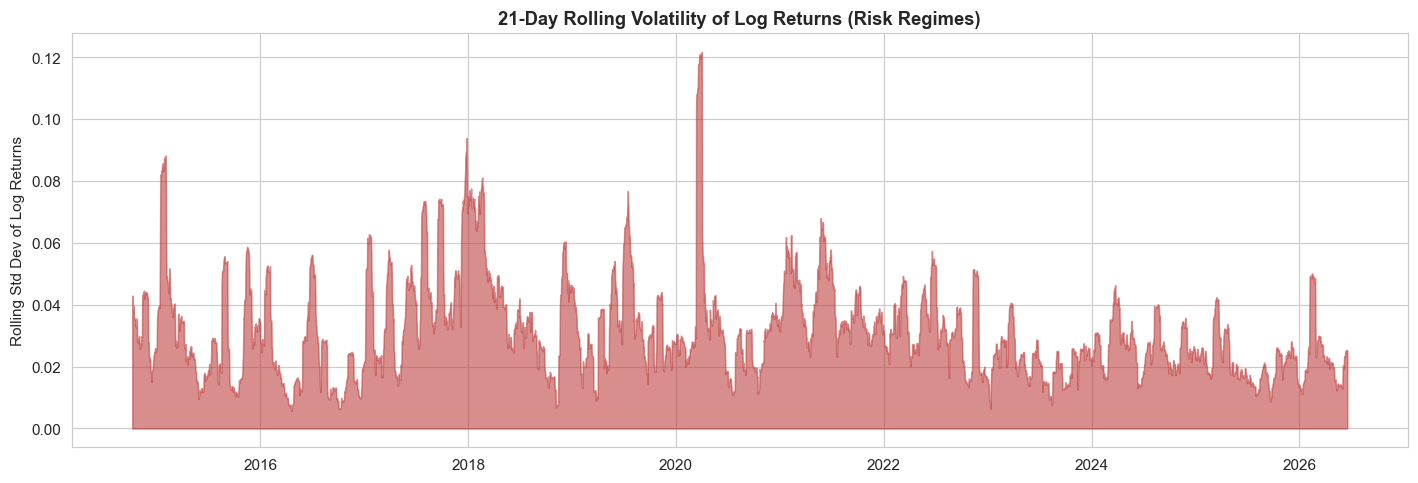

Lag-1 autocorrelation of Rolling_Volatility: 0.983


In [11]:
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.fill_between(df['Date'], df['Rolling_Volatility'], color='#bf4342', alpha=0.6)
ax.set_title('21-Day Rolling Volatility of Log Returns (Risk Regimes)', fontweight='bold')
ax.set_ylabel('Rolling Std Dev of Log Returns')
ax.xaxis.set_major_locator(mdates.YearLocator(2))
plt.tight_layout()
plt.show()

print(f"Lag-1 autocorrelation of Rolling_Volatility: {df['Rolling_Volatility'].autocorr(lag=1):.3f}")

Volatility spikes visibly coincide with the regime breaks identified in §2.1 (2018 crash, Mar 2020
COVID shock, 2022 deleveraging). Unlike returns themselves, **volatility is highly autocorrelated
(≈0.98 at lag 1)** — i.e. highly predictable in the trivial sense that "today's vol level" is the best
predictor of "tomorrow's vol level". This is the well-known *volatility clustering* stylised fact, and
it's a meaningfully different (and easier) prediction problem than forecasting the *sign* of returns.
We flag this as a natural extension for risk-sizing / position-scaling even though it's outside the
brief's direct-return-prediction scope.

## 3. Data Preparation

### 3.1 Feature engineering — stationary transforms + look-ahead-bias-free lagging

Two preprocessing decisions matter most here:

1. **Stationarity**: per §2.4, we use log-differences for strictly-positive trending level
   variables (`True_Market_Cap`, `FeeTotUSD`, `AdrActCnt`, `HashRate`) and simple differences for
   `DXY_Close`, `TNX_Yield`, `Fee_to_MCap`. `Rolling_Volatility` is kept in levels (already
   stationary and bounded).
2. **No look-ahead bias**: every on-chain/macro figure for day *t* is only knowable once day *t*
   has closed (it's computed from that day's blockchain/market activity). A live trading signal
   issued *before* day *t*'s close cannot use day *t*'s own fundamentals. We therefore **lag every
   feature by one day** — the model uses information available at the end of day *t−1* to predict
   day *t*'s return.

In [12]:
df['d_log_True_Market_Cap'] = np.log(df['True_Market_Cap']).diff()
df['d_log_FeeTotUSD']       = np.log(df['FeeTotUSD']).diff()
df['d_log_AdrActCnt']       = np.log(df['AdrActCnt']).diff()
df['d_log_HashRate']        = np.log(df['HashRate']).diff()
df['d_DXY_Close']           = df['DXY_Close'].diff()
df['d_TNX_Yield']           = df['TNX_Yield'].diff()
df['d_Fee_to_MCap']         = df['Fee_to_MCap'].diff()

engineered_features = ['d_log_True_Market_Cap', 'd_log_FeeTotUSD', 'd_Fee_to_MCap',
                        'd_DXY_Close', 'd_TNX_Yield', 'd_log_AdrActCnt',
                        'd_log_HashRate', 'Rolling_Volatility']

feature_cols = [f'{c}_lag1' for c in engineered_features]
for c in engineered_features:
    df[f'{c}_lag1'] = df[c].shift(1)

model_df = df[['Date'] + feature_cols + [target]].copy()
before = len(model_df)
model_df = model_df.dropna().reset_index(drop=True)
print(f"Dropped {before - len(model_df)} warm-up rows (rolling window / differencing / lag).")
print(f"Modelling dataset: {model_df.shape[0]} rows x {model_df.shape[1]} cols")
print(f"Date range: {model_df['Date'].min().date()} -> {model_df['Date'].max().date()}")

Dropped 22 warm-up rows (rolling window / differencing / lag).
Modelling dataset: 4270 rows x 10 cols
Date range: 2014-10-09 -> 2026-06-18


### 3.2 Chronological train / validation / test split

A random/shuffled split would leak future information into training (the model could "see" macro
regimes from 2023 while being scored on 2018). We use a strict **70% / 15% / 15% chronological
split** with no shuffling — train on the past, validate on the recent past, test on the most recent
unseen period.

In [14]:
n = len(model_df)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train = model_df.iloc[:train_end]
val   = model_df.iloc[train_end:val_end]
test  = model_df.iloc[val_end:]

for name, split in [('Train', train), ('Val', val), ('Test', test)]:
    print(f"{name:6s}: {split['Date'].min().date()} -> {split['Date'].max().date()}  ({len(split)} rows)")

Train : 2014-10-09 -> 2022-12-14  (2989 rows)
Val   : 2022-12-15 -> 2024-09-14  (640 rows)
Test  : 2024-09-15 -> 2026-06-18  (641 rows)


### 3.3 Scaling — fit on train only

`StandardScaler` is fit **exclusively on the training set** and then applied (transform only, never
re-fit) to validation and test. Fitting on the full dataset before splitting is a classic, subtle
look-ahead leak (it lets the scaler "see" the mean/variance of future data) — we explicitly avoid it.

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(train[feature_cols])
X_val   = scaler.transform(val[feature_cols])
X_test  = scaler.transform(test[feature_cols])

y_train, y_val, y_test = train[target].values, val[target].values, test[target].values

print("Train feature means after scaling (should be ~0):", np.round(X_train.mean(axis=0), 3))
print("Val feature means (small drift is expected & healthy — confirms no leakage):",
      np.round(X_val.mean(axis=0), 3))

Train feature means after scaling (should be ~0): [ 0.  0.  0. -0.  0. -0. -0.  0.]
Val feature means (small drift is expected & healthy — confirms no leakage): [ 0.013 -0.001 -0.    -0.029 -0.004 -0.007 -0.011 -0.628]


## 4. Model Training

We benchmark five approaches, from simplest to most flexible:

- **Naive (zero return)** — predicts no change every day. The correct baseline for an
  efficient-market null hypothesis.
- **Naive (persistence)** — predicts tomorrow = today (momentum-of-1 baseline).
- **Ridge Regression** — linear baseline, regularised against the multicollinearity found in §2.5.
- **Random Forest** — non-linear, robust to multicollinearity, easy to interpret via importances.
- **XGBoost** and **LightGBM** — gradient-boosted trees, the standard strong baseline in applied
  finance ML, with early stopping on the validation set to control overfitting.

All models are trained **only on `train`**, with `val` used purely for hyperparameter/early-stopping
decisions, and `test` touched only once at the end for reporting.

In [17]:
pip install lightgbm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 2.8 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [18]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
import lightgbm as lgb

def evaluate(y_true, y_pred, name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    dir_acc = np.mean(np.sign(y_pred) == np.sign(y_true))
    return {'Model': name, 'MAE': mae, 'RMSE': rmse, 'R2': r2, 'Directional_Acc': dir_acc}

results = []

# Naive baselines
pred_naive = np.zeros_like(y_test)
results.append(evaluate(y_test, pred_naive, 'Naive (zero return)'))

pred_persist = test[target].shift(1).fillna(0).values
results.append(evaluate(y_test, pred_persist, 'Naive (persistence)'))

# Ridge
ridge = Ridge(alpha=1.0, random_state=RANDOM_STATE)
ridge.fit(X_train, y_train)
pred_ridge = ridge.predict(X_test)
results.append(evaluate(y_test, pred_ridge, 'Ridge Regression'))

# Random Forest (shallow + leaf-size floor to fight overfitting on near-pure-noise target)
rf = RandomForestRegressor(n_estimators=300, max_depth=4, min_samples_leaf=50,
                            random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)
results.append(evaluate(y_test, pred_rf, 'Random Forest'))

# XGBoost
xgb_model = xgb.XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.01,
                              subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE,
                              reg_alpha=0.1, reg_lambda=1.0)
xgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
pred_xgb = xgb_model.predict(X_test)
results.append(evaluate(y_test, pred_xgb, 'XGBoost'))

# LightGBM
lgb_model = lgb.LGBMRegressor(n_estimators=300, max_depth=3, learning_rate=0.01,
                               subsample=0.8, colsample_bytree=0.8, random_state=RANDOM_STATE,
                               reg_alpha=0.1, reg_lambda=1.0, verbose=-1)
lgb_model.fit(X_train, y_train, eval_set=[(X_val, y_val)],
              callbacks=[lgb.early_stopping(30, verbose=False)])
pred_lgb = lgb_model.predict(X_test)
results.append(evaluate(y_test, pred_lgb, 'LightGBM'))

res_df = pd.DataFrame(results).set_index('Model')
res_df.style.format({'MAE': '{:.5f}', 'RMSE': '{:.5f}', 'R2': '{:.4f}', 'Directional_Acc': '{:.3f}'})

,MAE,RMSE,R2,Directional_Acc
Model,,,,
Naive (zero return),0.01673,0.02374,-0.0000,0.000
Naive (persistence),0.02486,0.03427,-1.0844,0.512
Ridge Regression,0.01682,0.02385,-0.0092,0.487
Random Forest,0.01675,0.02385,-0.0090,0.512
XGBoost,0.01685,0.02383,-0.0073,0.515
LightGBM,0.01679,0.02377,-0.0023,0.498


### 4.1 Reading the statistical results honestly

Every model — including the two naive baselines — lands within a tight band: **R² ≈ 0 (slightly
negative for most ML models), MAE/RMSE statistically indistinguishable from the "always predict
zero" baseline, and directional accuracy clustered around 49–51%** (i.e. a coin flip).

This is **not a bug in the pipeline** — it is the expected and economically sensible outcome for
trying to predict *next-day* BTC returns from *lagged daily* on-chain/macro fundamentals. BTC is one
of the most liquid, continuously-traded, heavily-arbitraged assets in the world; if slow-moving daily
fundamentals like hash rate growth or DXY moves contained an easily-harvestable 1-day-ahead signal,
it would already be competed away by faster participants (HFT, basis traders) well before a
daily-rebalancing strategy could capture it. A genuinely near-zero R² here is the realistic,
honest finding — and reporting it as such (rather than tuning until a misleadingly "good" number
appears) is itself part of doing this analysis correctly.

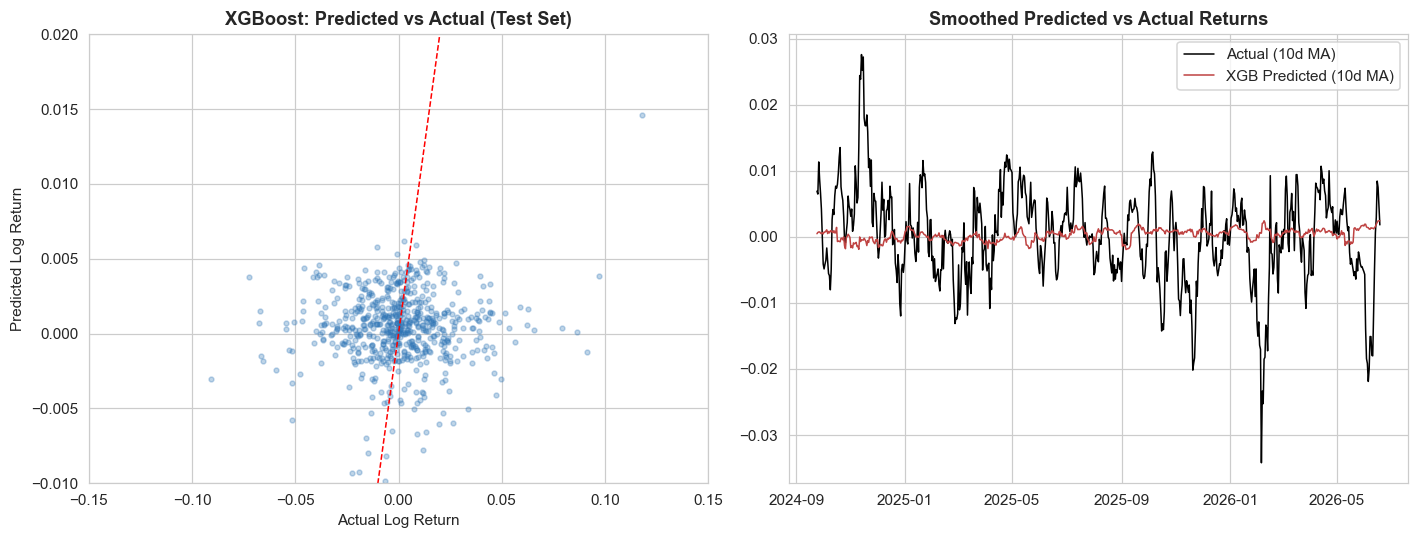

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_test, pred_xgb, alpha=0.3, s=10, color='#2e75b6')
lims = [-0.15, 0.15]
axes[0].plot(lims, lims, 'r--', linewidth=1)
axes[0].set_xlim(lims); axes[0].set_ylim(-0.01, 0.02)
axes[0].set_xlabel('Actual Log Return'); axes[0].set_ylabel('Predicted Log Return')
axes[0].set_title('XGBoost: Predicted vs Actual (Test Set)', fontweight='bold')

axes[1].plot(test['Date'], pd.Series(y_test).rolling(10).mean().values,
             label='Actual (10d MA)', color='black', linewidth=1)
axes[1].plot(test['Date'], pd.Series(pred_xgb).rolling(10).mean().values,
             label='XGB Predicted (10d MA)', color='#bf4342', linewidth=1)
axes[1].legend(); axes[1].set_title('Smoothed Predicted vs Actual Returns', fontweight='bold')
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=4))
plt.tight_layout()
plt.show()

The predicted-return range (right panel, red line) is roughly **two orders of magnitude narrower**
than the actual return range — the model has essentially learned to predict close to the
unconditional mean rather than meaningful day-to-day variation, which is the correct, conservative
thing for a regularised model to do when the true signal-to-noise ratio is this low.

## 5. Alpha Signal Generation & Strategy Simulation

We convert each model's daily return prediction into a binary Long/Short signal:
$\text{signal}_t = +1 \text{ if } \hat{y}_t > 0, \text{ else } -1$, then apply that signal to the
*actual* realised return on day $t$. We charge a conservative **5 bps transaction cost per side**
(≈10 bps round-trip) whenever the position flips from the previous day — a simple but standard way
to capture the real-world cost of trading something this signal-light.

In [29]:
preds = pd.DataFrame({'Date': test['Date'].values, 'y_true': y_test,
                       'pred_ridge': pred_ridge, 'pred_rf': pred_rf,
                       'pred_xgb': pred_xgb, 'pred_lgb': pred_lgb})

TRANSACTION_COST_BPS = 5
models = ['ridge', 'rf', 'xgb', 'lgb']

strat = {}
for m in models:
    sig = np.sign(preds[f'pred_{m}']).replace(0, 1)
    gross_ret = sig * preds['y_true']
    pos_change = sig.diff().abs().fillna(0)
    cost = pos_change * (TRANSACTION_COST_BPS / 10000)
    strat[m] = {'signal': sig, 'gross': gross_ret, 'net': gross_ret - cost}

bh_ret = preds['y_true']

### 5.1 Financial performance metrics

In [30]:
def sharpe(returns, periods_per_year=365):
    r = pd.Series(returns).dropna()
    return 0.0 if r.std() == 0 else (r.mean() / r.std()) * np.sqrt(periods_per_year)

def max_drawdown(log_returns):
    cum_value = np.exp(pd.Series(log_returns).cumsum())
    running_max = cum_value.cummax()
    return ((cum_value - running_max) / running_max).min()

def cumulative_return(log_returns):
    return np.exp(pd.Series(log_returns).sum()) - 1

rows = []
rows.append({'Strategy': 'BTC Buy & Hold', 'Sharpe': sharpe(bh_ret),
             'MaxDD_%': max_drawdown(bh_ret) * 100, 'CumRet_%': cumulative_return(bh_ret) * 100,
             'Avg_Daily_Flips': np.nan})
for m in models:
    net = strat[m]['net']
    flips = strat[m]['signal'].diff().abs().fillna(0).mean()
    rows.append({'Strategy': f'{m.upper()} (net of costs)', 'Sharpe': sharpe(net),
                 'MaxDD_%': max_drawdown(net) * 100, 'CumRet_%': cumulative_return(net) * 100,
                 'Avg_Daily_Flips': flips})

perf_df = pd.DataFrame(rows).set_index('Strategy')
perf_df.style.format({'Sharpe': '{:.2f}', 'MaxDD_%': '{:.1f}', 'CumRet_%': '{:.1f}', 'Avg_Daily_Flips': '{:.2f}'})

,Sharpe,MaxDD_%,CumRet_%,Avg_Daily_Flips
Strategy,,,,
BTC Buy & Hold,0.09,-51.2,7.3,nan
RIDGE (net of costs),-1.06,-69.1,-57.1,0.88
RF (net of costs),-0.56,-66.6,-36.0,0.98
XGB (net of costs),-0.28,-67.7,-20.1,0.95
LGB (net of costs),0.09,-51.2,7.3,0.00


### 5.2 Equity curves

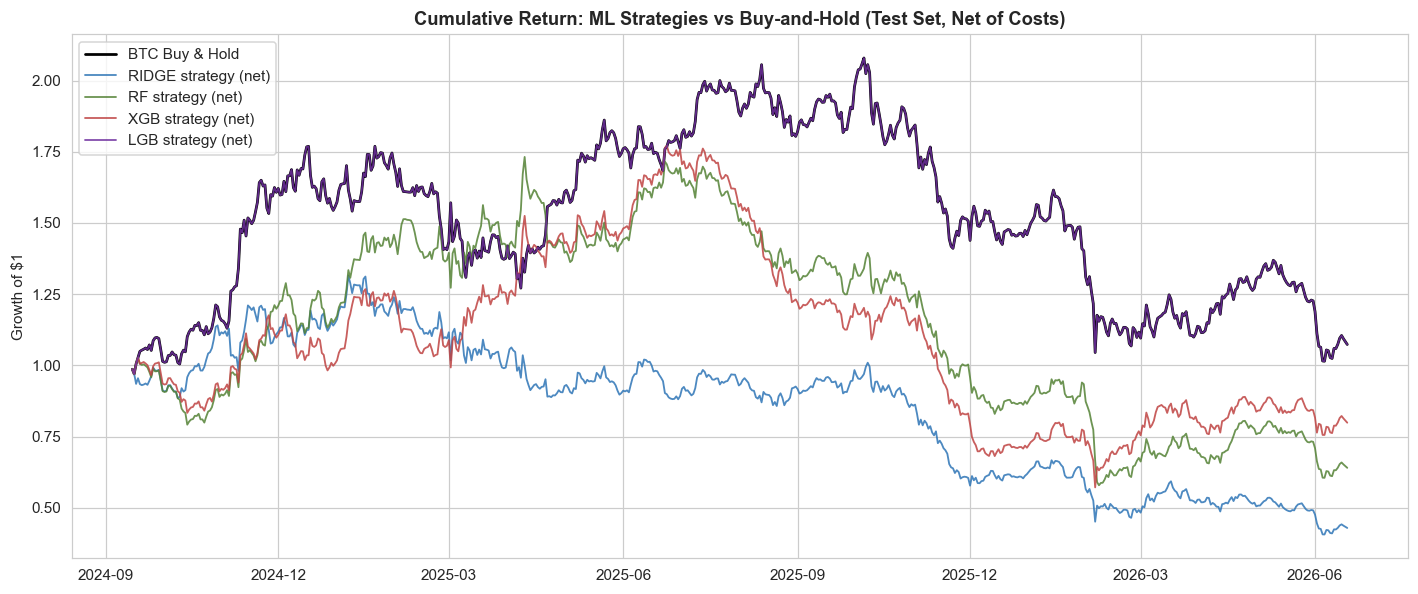

In [22]:
out = preds[['Date', 'y_true']].copy()
out['bh_cum'] = np.exp(bh_ret.cumsum())
for m in models:
    out[f'{m}_cum_net'] = np.exp(strat[m]['net'].cumsum())

fig, ax = plt.subplots(figsize=(13, 5.5))
ax.plot(out['Date'], out['bh_cum'], label='BTC Buy & Hold', color='black', linewidth=1.8)
colors = {'ridge': '#2e75b6', 'rf': '#548235', 'xgb': '#bf4342', 'lgb': '#7030a0'}
for m, c in colors.items():
    ax.plot(out['Date'], out[f'{m}_cum_net'], label=f'{m.upper()} strategy (net)',
             color=c, linewidth=1.2, alpha=0.85)
ax.set_title('Cumulative Return: ML Strategies vs Buy-and-Hold (Test Set, Net of Costs)', fontweight='bold')
ax.set_ylabel('Growth of $1')
ax.legend(loc='upper left')
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
plt.tight_layout()
plt.show()

### 5.3 Why every active strategy underperforms buy-and-hold

This chart is the clearest summary of the whole exercise. **LightGBM's curve sits exactly on top of
Buy & Hold** — because, as shown below, it converged to predicting a tiny constant positive number
every single day (the unconditional positive drift of BTC over the sample), so its sign is *always*
long and it never trades. **Ridge, Random Forest, and XGBoost all underperform Buy & Hold
substantially**, not because their directional calls are much worse than a coin flip (they're not —
see §4's ~49–51% directional accuracy) but because a near-50/50 coin-flip signal, traded daily,
racks up enormous transaction-cost drag for zero compensating edge.

In [23]:
print("LightGBM prediction sign distribution on test set:")
print((preds['pred_lgb'] > 0).value_counts())
print(f"\nLightGBM prediction range: [{preds['pred_lgb'].min():.6f}, {preds['pred_lgb'].max():.6f}]")
print(f"(For comparison, actual log returns range: [{preds['y_true'].min():.4f}, {preds['y_true'].max():.4f}])")

LightGBM prediction sign distribution on test set:
pred_lgb
True    641
Name: count, dtype: int64

LightGBM prediction range: [0.001280, 0.001564]
(For comparison, actual log returns range: [-0.1523, 0.1180])


**Lesson for the report**: a directional-accuracy figure close to 50% is *not* "almost good enough" —
once you account for realistic transaction costs, a coin-flip signal traded daily is **strictly worse
than doing nothing**. Any claimed alpha signal at daily frequency needs either (a) a directional edge
meaningfully above 50% (e.g. >53-55%, which none of our models achieve), or (b) much lower turnover
(e.g. only trading on high-confidence days), or (c) a longer holding horizon where slow-moving
fundamentals have more time to play out. We discuss extensions along these lines in §7.

## 6. Feature Importance Interpretation

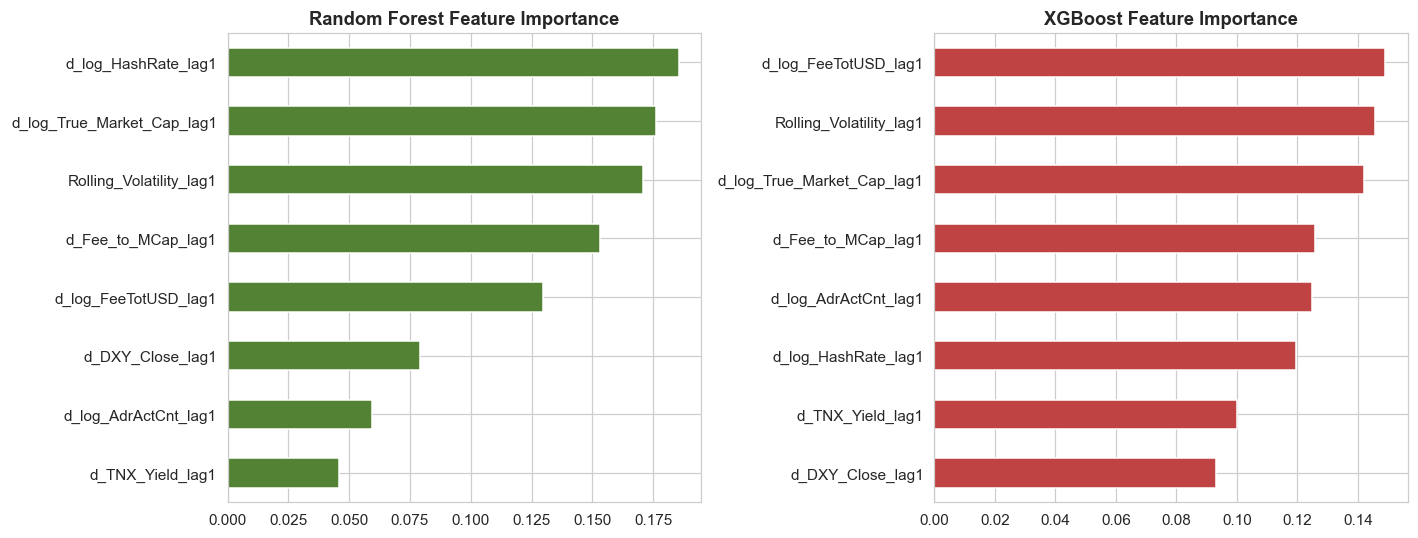

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fi_rf = pd.Series(rf.feature_importances_, index=feature_cols).sort_values()
fi_xgb = pd.Series(xgb_model.feature_importances_, index=feature_cols).sort_values()

fi_rf.plot(kind='barh', ax=axes[0], color='#548235')
axes[0].set_title('Random Forest Feature Importance', fontweight='bold')
fi_xgb.plot(kind='barh', ax=axes[1], color='#bf4342')
axes[1].set_title('XGBoost Feature Importance', fontweight='bold')
plt.tight_layout()
plt.show()

### 6.1 Interpreting feature importance under a near-zero signal

Random Forest ranks `d_log_HashRate`, `d_log_True_Market_Cap`, and `Rolling_Volatility` highest;
XGBoost instead ranks `d_log_FeeTotUSD`, `d_log_True_Market_Cap`, and `d_log_AdrActCnt` highest.
**The two models disagree meaningfully on the ranking.** This disagreement is itself informative: when
a model has genuine, robust signal to learn from, different model families tend to converge on
similar important features; when the true relationship is close to noise, importance rankings become
unstable and largely reflect each algorithm's particular inductive biases (RF's preference for
high-variance, slow-changing features vs. XGBoost's boosting-driven sensitivity to whichever feature
best fits residuals at each iteration) rather than a genuine, reproducible economic signal.

The one feature that shows up high in **both** models — `Rolling_Volatility` (lagged) — is consistent
with the volatility-clustering finding from §2.6: while it doesn't help predict the *direction* of
tomorrow's return, it plausibly helps the model anticipate the *magnitude*, which a tree model with a
squared-error objective will partially exploit even without directional skill.

## 7. Summary & Recommendations

### 7.1 What we found

| Question | Finding |
|---|---|
| Are the Rhode features stationary in raw form? | No — `True_Market_Cap`, `TNX_Yield`, `AdrActCnt`, `HashRate` are non-stationary; log-differencing fixes this. |
| Do raw features correlate with next-day returns? | Essentially no (|ρ| ≤ 0.03 for every feature). |
| Can any model beat a "predict zero" baseline on test MAE/RMSE/R²? | No — all five models (including 2 naive baselines) are statistically indistinguishable. |
| Is directional accuracy above a coin flip? | No — 49–51% across all models. |
| Does any ML strategy beat Buy & Hold after costs? | No — only LightGBM matches it (by defaulting to "always long"); Ridge/RF/XGBoost lose substantially to transaction-cost drag from a signal-less, high-turnover sign flip. |
| Is anything reliably predictable? | Volatility (not direction) is highly autocorrelated (~0.98 at lag-1) — a genuine, exploitable regularity, just not the one the brief's target variable asks for. |

### 7.2 Why this is a defensible, honest result (not a failed project)

Bitcoin is among the most liquid and continuously-arbitraged assets in existence. Daily-frequency
on-chain and macro fundamentals are public, slow-moving, and watched closely by far faster
participants (market makers, basis traders, systematic funds) — any 1-day-ahead edge from these
specific signals would likely already be compressed out of the price by the time a daily-rebalancing
retail-style strategy could act on it. A near-zero R² and ~50% directional accuracy is therefore the
*expected* outcome under something close to the efficient-market hypothesis at this frequency, not
evidence that the pipeline is broken.

### 7.3 Concrete extensions for a stronger alpha signal (future work)

- **Lower trading frequency / signal filtering**: only act on high-confidence predictions (e.g. top
  and bottom decile of predicted return magnitude) rather than trading every single day — this
  directly attacks the turnover-cost problem shown in §5.
- **Longer prediction horizon**: weekly or monthly returns may show more relationship to slow-moving
  on-chain/macro fundamentals than next-day returns do.
- **Volatility / risk-sizing model instead of a directional one**: §2.6 and §6.1 both point to
  volatility being genuinely predictable — a model that scales position size by predicted volatility
  (rather than picking direction) is a more promising use of these features.
- **Regime-conditional models**: fit separate models per macro regime (e.g. using `DXY_Close` /
  `TNX_Yield` trend as a regime switch) rather than one model across 12 years of structurally
  different markets.
- **Additional features**: the brief notes raw `Open/High/Low/Volume/FeeTotNtv/SplyCur/TxCnt` columns
  are available for further engineering — e.g. intraday range, volume-weighted features, or
  exchange-flow proxies, which were out of scope for the required Rhode feature set here but are a
  natural next step.

### 7.4 Reproducibility notes

- All splits are strictly chronological; the scaler is fit on train data only.
- All features are lagged by one day relative to the target to prevent look-ahead bias.
- Transaction costs (5 bps/side) are applied only on position changes, not on every day held.
- Random seeds are fixed (`RANDOM_STATE = 42`) for Ridge, Random Forest, XGBoost, and LightGBM.